# Assignment 1 — Check-in (not graded)
**ENGS 3302 Pattern Recognition · Week 1** · Submit this notebook (`.ipynb`) on Moodle with all cells run.

This assignment has **no grade**. It checks that your tools work and lets you practise submitting on Moodle.
Use what you saw in Lab 1.

In [ ]:
# Run this cell first. It loads the libraries and a helper that checks your answers.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine

def check(label, got, expected, tol=1e-3):
    """Prints a green tick if `got` is close to `expected`, otherwise a red cross."""
    try:
        ok = got is not None and np.allclose(np.asarray(got, dtype=float),
                                             np.asarray(expected, dtype=float), atol=tol)
    except Exception:
        ok = False
    print(f"✅ {label}" if ok else f"❌ {label}: expected {expected}, got {got}")

print("Ready.")

Ready.


### Task 1 — Your environment
Run the cell. It prints the versions of your tools.

In [ ]:
import sys, sklearn
print("Python ", sys.version.split()[0])
print("NumPy  ", np.__version__, "| Pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("Running on Colab" if "google.colab" in sys.modules else "Running on my laptop")

Python  3.13.16
NumPy   2.1.3 | Pandas 2.2.3 | scikit-learn 1.6.1
Running on Colab


### Task 2 — The Wine dataset in numbers
`load_wine(as_frame=True)` loads 178 wines from 3 cultivars, with 13 chemical features.
Print the number of samples, the number of features, and the number of wines in each class.

In [ ]:
data = load_wine(as_frame=True)
df = data.frame

print(f"Number of samples: {df.shape[0]}")
print(f"Number of features: {df.shape[1] - 1}")  # باستثناء عمود الهدف target
print("Number of wines in each class:")
print(df['target'].value_counts().sort_index())

Number of samples: 178
Number of features: 13
Number of wines in each class:
target
0    59
1    71
2    48
Name: count, dtype: int64


### Task 3 — Two features in feature space
Choose **two** features and draw a scatter plot coloured by class (as in Lab 1, Section 1.4).
In 2 sentences: do these two features separate the three classes well?


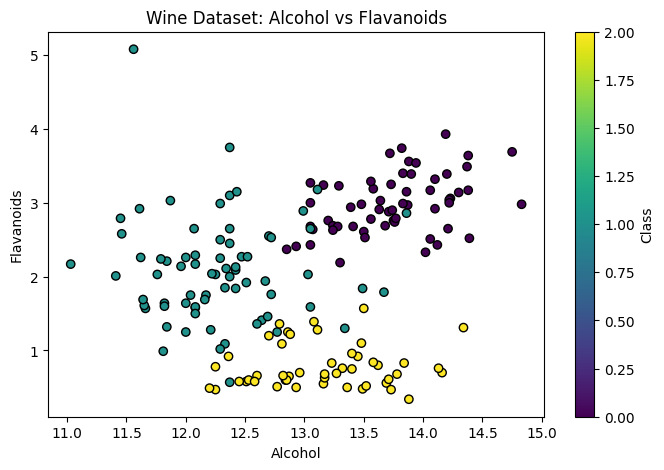

In [ ]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df['alcohol'], df['flavanoids'], c=data.target, cmap='viridis', edgecolor='k')
plt.xlabel('Alcohol')
plt.ylabel('Flavanoids')
plt.title('Wine Dataset: Alcohol vs Flavanoids')
plt.colorbar(scatter, label='Class')
plt.show()

*Your answer:* Yes, these two features (alcohol and flavanoids) separate the three classes reasonably well, with Class 0 forming a clear cluster at high values for both features. Although there is a slight overlap between Class 1 and Class 2, they remain largely distinguishable based on their flavanoid levels.

### Task 4 — A one-feature rule
Write a rule on **one** feature that separates class `0` from the other two classes, and count its errors on all 178 wines.

In [ ]:
# قاعدة بسيطة: إذا كان مستوى الفلافونويد أكبر من 2.0 فهي الفئة 0، وإلا فلا
true_classes = data.target == 0
predicted_classes = df['flavanoids'] > 2.0

# حساب الأخطاء (التنبؤ الخاطئ)
errors = np.sum(predicted_classes != true_classes)
print(f"Number of classification errors: {errors}")

Number of classification errors: 38


### Task 5 — Pattern recognition in your life
Describe one pattern recognition system you use. Name its **raw data**, two possible **features**, and its **classes**.

*Your answer:* *
* **System:** Fingerprint Recognition System (used for smartphone unlocking or attendance systems).
* **Raw Data:** The raw digital image of the fingerprint captured by the sensor.
* **Two Features:**
  1. Locations and directions of minutiae points (ridge endings and bifurcations).
  2. Ridge spacing and overall pattern orientation.
* **Classes:** Match (Authorized User) vs. No Match (Unauthorized User).